In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 6.9 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully.")

YOLO model loaded successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving cctv.mp4 to cctv.mp4


In [ ]:
import os

print("Files in current directory:")
print(os.listdir())

Files in current directory:
['.config', 'yolo11n.pt', 'cctv.mp4', 'sample_data']


In [ ]:
results = model.predict(
    source="cctv.mp4",
    save=True,
    conf=0.5
)

print("Object detection completed.")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/310) /content/cctv.mp4: 640x384 1 person, 1 car, 1 motorcycle, 444.4ms
video 1/1 (frame 2/310) /content/cctv.mp4: 640x384 1 person, 1 car, 1 motorcycle, 125.0ms
video 1/1 (frame 3/310) /content/cctv.mp4: 640x384 1 person, 1 car, 1 motorcycle, 170.3ms
video 1/1 (frame 4/310) /content/cctv.mp4: 640x384 1 person, 1 car, 1 motorcycle, 148.0ms
video 1/1 (frame 5/310) /content/cctv.mp4: 640x384 1 person, 1 motorcycle, 135.2ms
video 1/1 (frame

In [ ]:
import os

for root, dirs, files_list in os.walk("runs"):
    for file in files_list:
        if file.endswith(".mp4"):
            print(os.path.join(root, file))

In [ ]:
from IPython.display import HTML
from base64 import b64encode

video_path = "runs/detect/predict/cctv.mp4"

mp4 = open(video_path, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML(f'''
<video width="800" controls>
    <source src="{data_url}" type="video/mp4">
</video>
''')

FileNotFoundError: [Errno 2] No such file or directory: 'runs/detect/predict/cctv.mp4'

In [ ]:
import os

for root, dirs, files in os.walk("/content/runs"):
    for file in files:
        print(os.path.join(root, file))

/content/runs/detect/predict/cctv.avi


In [1]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

In [2]:
import cv2

video = cv2.VideoCapture("/content/cctv.mp4")

success, frame = video.read()

video.release()

print("Frame extracted:", success)

Frame extracted: True


In [3]:
results = model.predict(
    source=frame,
    conf=0.5
)

print("Object detection completed.")


0: 640x384 1 person, 1 car, 1 motorcycle, 365.7ms
Speed: 49.0ms preprocess, 365.7ms inference, 31.3ms postprocess per image at shape (1, 3, 640, 384)
Object detection completed.


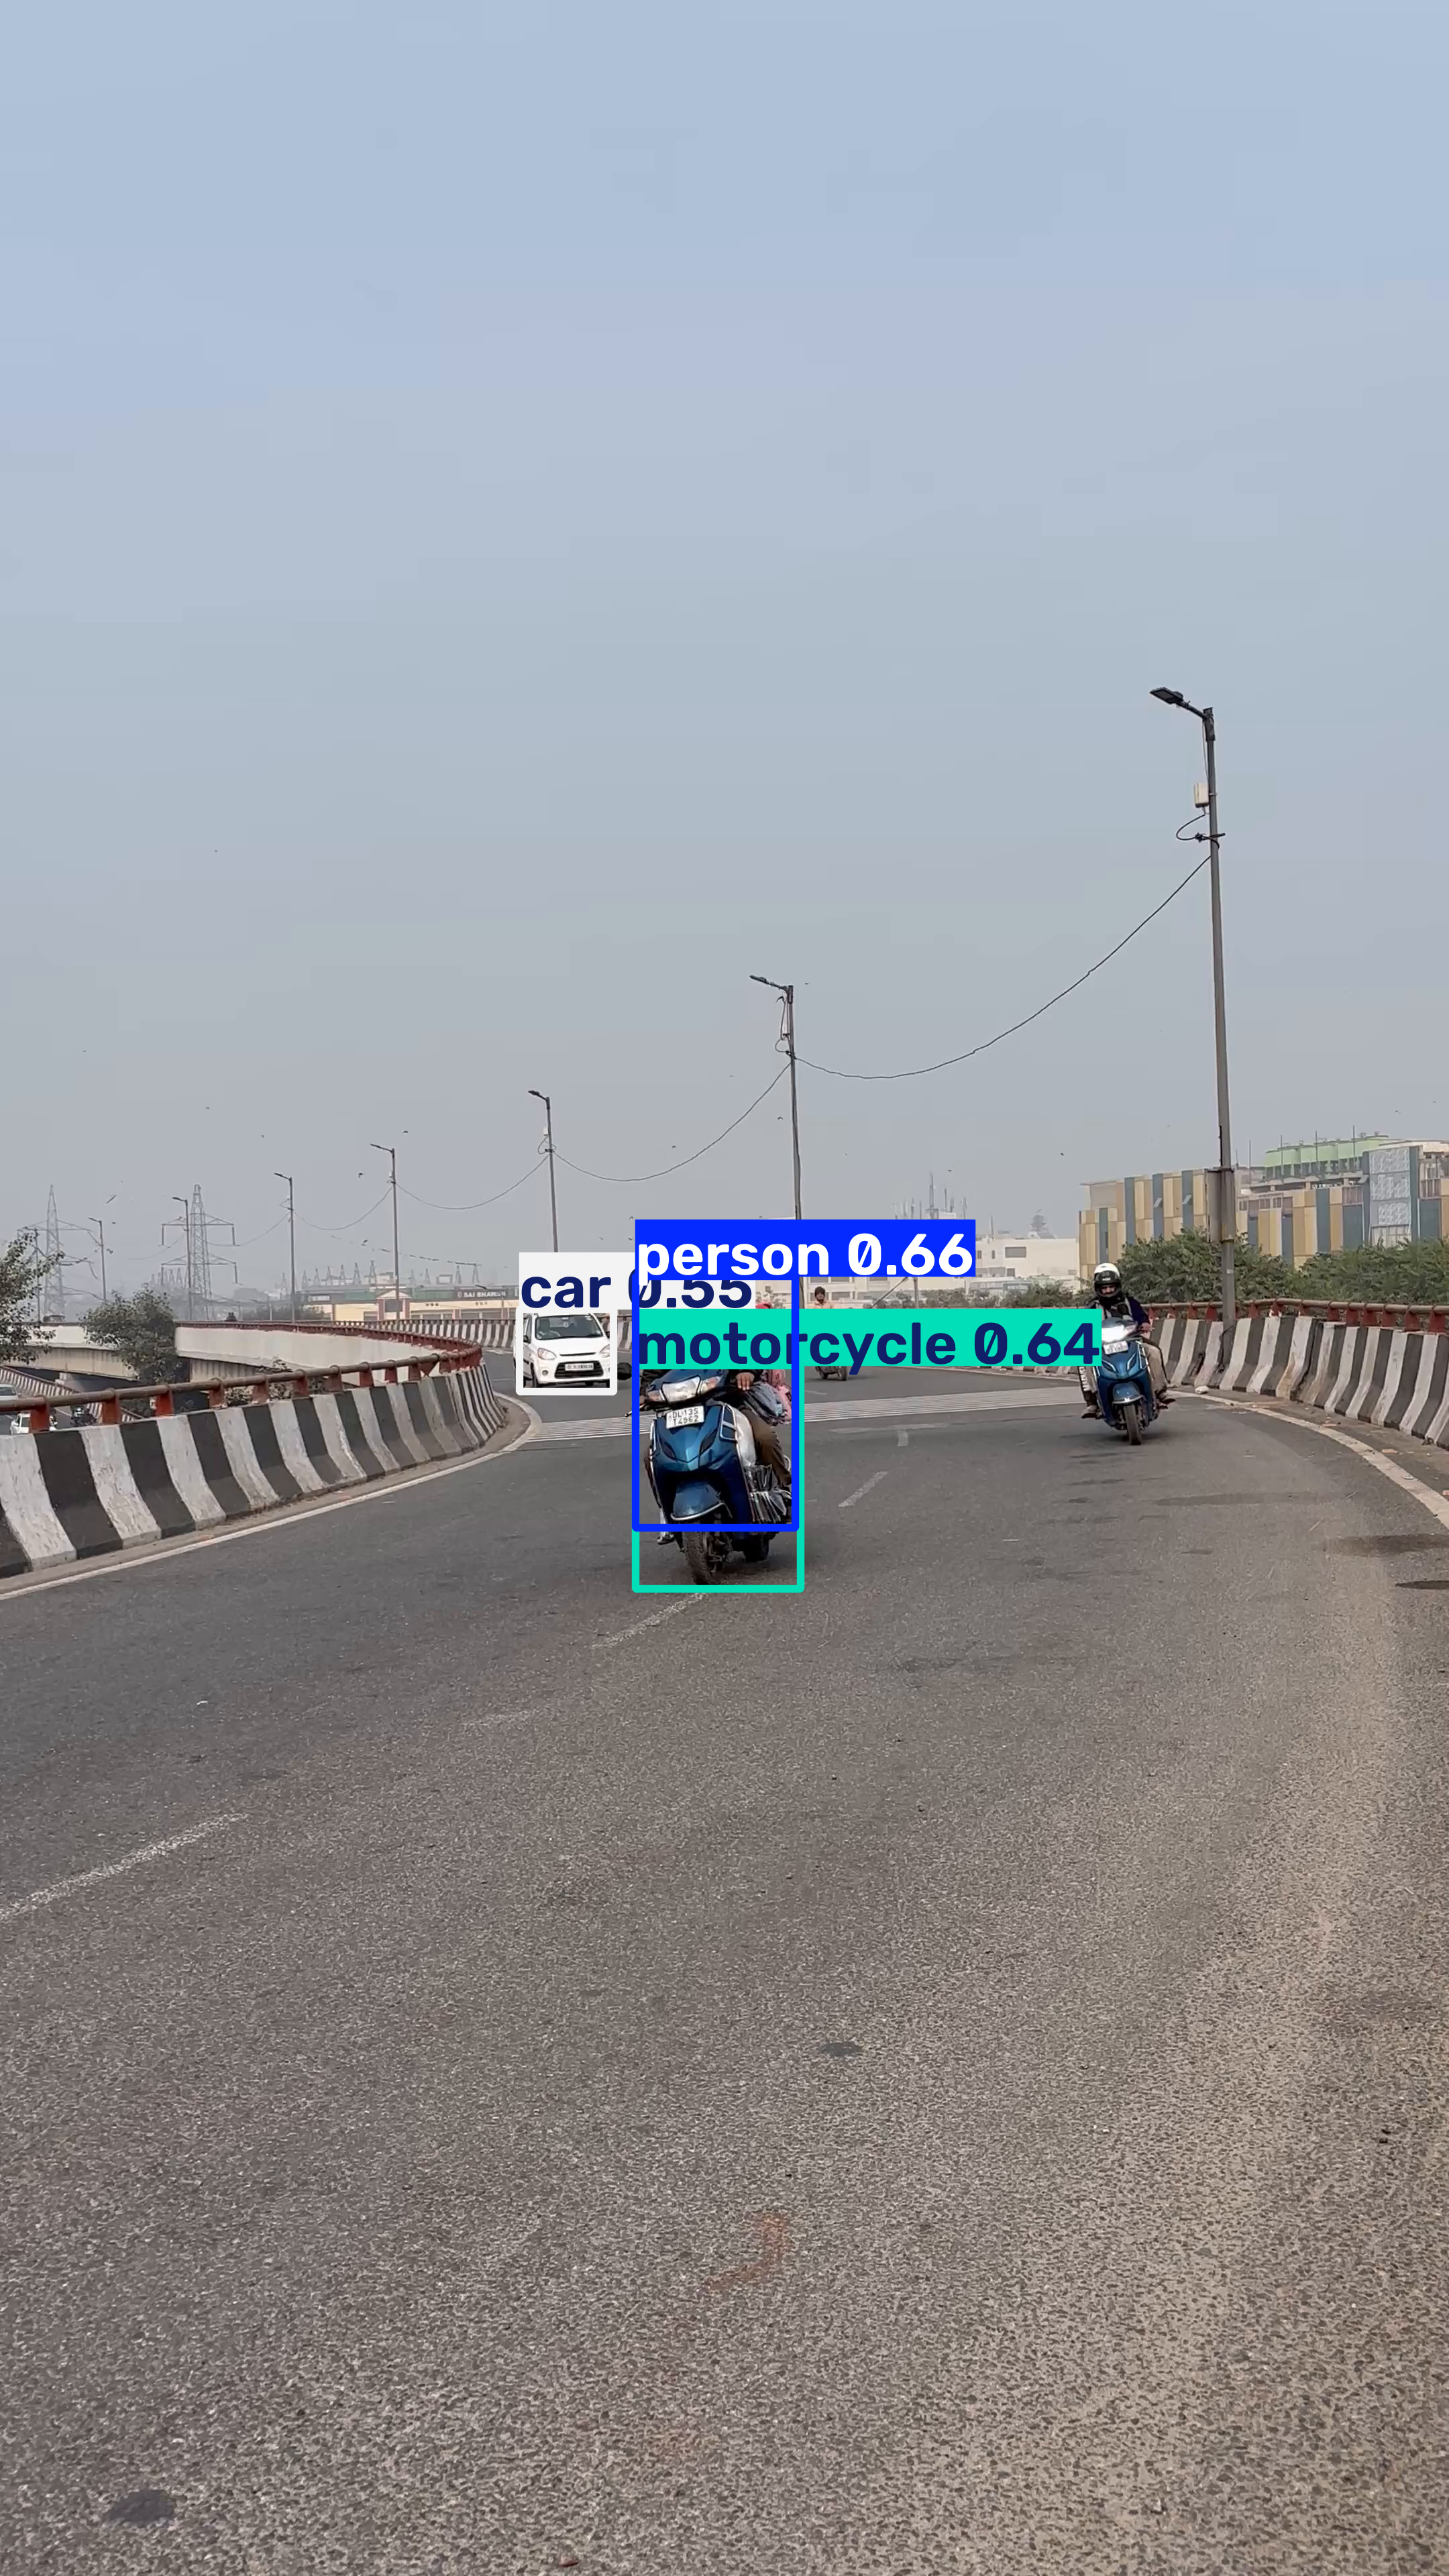

In [4]:
results[0].show()